In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

In [2]:
def inter_from_256(x):
    return np.interp(x=x,xp=[0,255],fp=[0,1])

In [3]:
data_home ="data/majority_move_lin/"

beta = 0.2
q=0.3
beta_str=str(np.round(beta, 2)).replace('.', '')
q_str=str(np.round(q, 1)).replace('.', '')
filename = f"2_regular_edgesize_5_maj_change_lin_beta_{beta_str}_q_{q_str}_r_1.csv"

In [30]:
#color pinterest
color1=(inter_from_256(231),inter_from_256(197),inter_from_256(108))
color2=(inter_from_256(189),inter_from_256(108),inter_from_256(78))
color3=(inter_from_256(215),inter_from_256(66),inter_from_256(232))
color4=(inter_from_256(86),inter_from_256(141),inter_from_256(162))

colors=[color1,color2,color3,color4]

In [5]:
filename

'2_regular_edgesize_5_maj_change_lin_beta_02_q_03_r_1.csv'

In [6]:
df = pd.read_csv(data_home + filename)


In [7]:
df.head()

,sample id,datatype,0,1,2,3,4,5,6,7,...,291,292,293,294,295,296,297,298,299,300
0,0,sum_opinion_A,500,500,503,505,505,505,509,510,...,460,460,460,460,460,461,462,462,462,461.0
1,0,binned_opinions_home,9 31 52 70 35 3,11 36 42 68 36 7,14 36 41 59 40 10,16 39 37 53 42 13,19 37 39 47 41 17,22 33 38 47 41 19,27 26 45 41 34 27,28 29 38 42 30 33,...,107 1 0 0 1 91,107 1 0 0 1 91,107 1 0 0 1 91,107 1 0 0 1 91,107 0 1 0 1 91,107 0 0 1 1 91,107 0 0 1 1 91,107 0 0 1 1 91,107 0 1 0 1 91,NaN
2,0,binned_opinions_wp,4 0 43 0 55 0 51 0 41 6,18 5 28 10 19 31 38 7 31 13,26 7 21 11 14 35 35 10 21 20,31 1 26 12 15 24 32 16 21 22,38 4 15 11 15 26 28 26 17 20,36 3 15 20 13 20 37 16 10 30,33 6 17 21 9 25 30 11 17 31,36 8 16 14 9 26 29 9 19 34,...,104 0 0 0 0 0 0 0 0 96,104 0 0 0 0 0 0 0 0 96,104 0 0 0 0 0 0 0 0 96,104 0 0 0 0 0 0 0 0 96,104 0 0 0 0 0 0 0 0 96,103 0 1 0 0 0 0 0 0 96,103 0 1 0 0 0 0 0 0 96,103 0 1 0 0 0 0 0 0 96,103 0 1 0 0 0 0 0 1 95,NaN
3,0,binned_edge_sizes_wp,0 0 0 0 0 200 0 0 0 0 0 0 0 0,0 0 0 7 44 98 44 7 0 0 0 0 0 0,0 0 1 20 46 72 40 15 5 1 0 0 0 0,0 0 1 30 45 64 27 25 4 1 3 0 0 0,0 1 7 26 48 49 32 25 8 2 1 1 0 0,0 2 5 37 35 48 34 24 10 5 0 0 0 0,0 3 5 36 31 43 47 25 8 1 1 0 0 0,0 3 8 35 29 44 43 27 7 3 1 0 0 0,...,0 26 20 26 28 28 10 18 13 13 10 4 1 2,0 26 20 26 28 28 10 18 13 13 10 4 1 2,0 26 20 26 28 28 10 18 13 13 10 4 1 2,0 26 20 26 28 28 10 18 13 13 10 4 1 2,0 26 20 26 28 28 10 18 13 13 10 4 1 2,0 26 20 26 28 27 11 18 13 13 11 3 1 2,0 26 20 26 28 27 11 18 13 13 11 3 1 2,0 26 20 26 28 27 11 18 13 13 11 3 1 2,0 26 20 26 28 27 11 18 13 13 11 3 1 2,NaN
4,1,sum_opinion_A,500,500,497,488,487,486,494,483,...,485,485,485,485,485,485,485,485,485,485.0


In [8]:
results={}

row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp']
iterations=300
for row_i,row in enumerate(row_names):
    results[row]=[]
    if row != 'sum_opinion_A':
        pdrow=list(df.iloc[[row_i]].values[0])
        for j in range(len(pdrow[2].split(' '))):
                results[row].append([])
                
    for i in range(iterations):
        pdrow=list(df.iloc[[i * len(row_names) + row_i]].values[0])        
        if row != 'sum_opinion_A':
            for j,k in enumerate(pdrow[2].split(' ')):
                    results[row][j].append([])
            for item in pdrow[2:-1]:
                for j,k in enumerate(item.split(' ')):
                    results[row][j][i].append(int(k))
        else:
            try:
                results[row].append([int(item)for item in pdrow[2:-1]])
            except:
                print(i)
                break

## Time evolution of 'A' opinions 

In [9]:
fs=20
ts=15

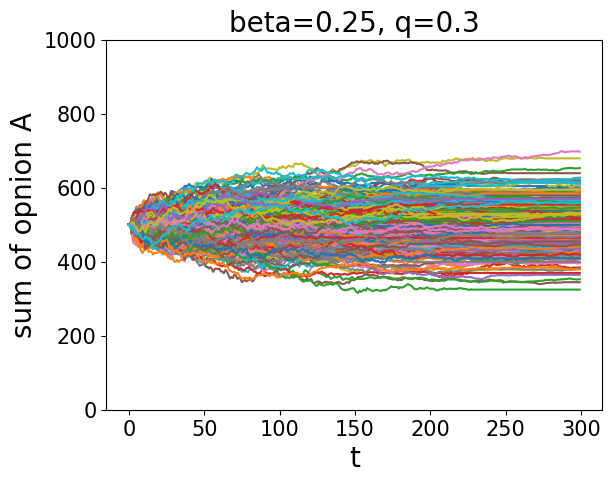

In [10]:
fig,ax=plt.subplots()
beta = 0.25
q=0.3
for i in range(iterations):
    ax.plot(results['sum_opinion_A'][i])
ax.set_ylabel('sum of opnion A',fontsize=fs)
ax.set_xlabel('t',fontsize=fs)
ax.set_title(f'{beta=}, {q=}',fontsize=fs)
ax.tick_params('both', labelsize=ts)
ax.set_ylim(0,1000)
plt.savefig('')
plt.show()

In [11]:
iterations

300

In [12]:
import scipy.stats

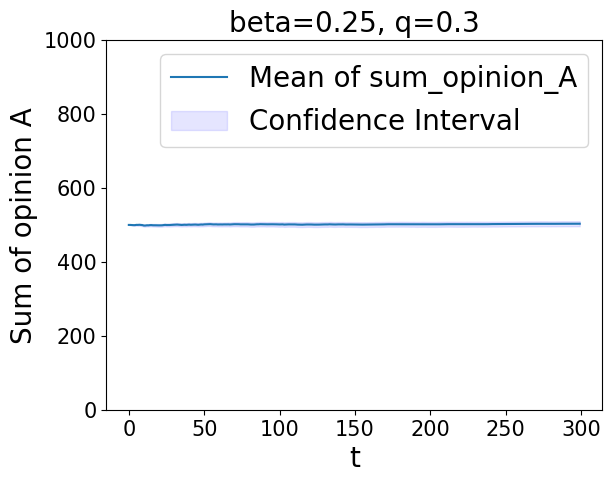

In [13]:
# Assuming `results['sum_opinion_A']` is a list of arrays where each array corresponds to an iteration
iterations = len(results['sum_opinion_A'])
t_steps = len(results['sum_opinion_A'][0])

# Convert to a NumPy array for easier calculations: shape (iterations, t_steps)
data = np.array(results['sum_opinion_A'])

# Calculate the mean and 95% confidence interval
mean_values = np.mean(data, axis=0)

conflev = 0.05
t_value = scipy.stats.t.ppf(1 - conflev / 2, iterations - 1)
ci = t_value * np.std(data, axis=0) / np.sqrt(iterations)
y_ci_lower=mean_values - ci
y_ci_upper=mean_values + ci


# Plotting
fig, ax = plt.subplots()
ax.plot(mean_values, label='Mean of sum_opinion_A')
ax.fill_between(range(t_steps), y_ci_lower, y_ci_upper, color='b', alpha=0.1, label='Confidence Interval')

# Labels and title
ax.set_ylabel('Sum of opinion A', fontsize=fs)
ax.set_xlabel('t', fontsize=fs)
ax.set_title(f'{beta=}, {q=}', fontsize=fs)
ax.tick_params('both', labelsize=ts)
ax.set_ylim(0,1000)

# Legend
ax.legend(fontsize=fs)

# Show plot
plt.show()


In [14]:
import numpy as np
import scipy.stats

def mean_confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), scipy.stats.sem(a)
    h = se * scipy.stats.t.ppf((1 + confidence) / 2., n-1)
    return m, h

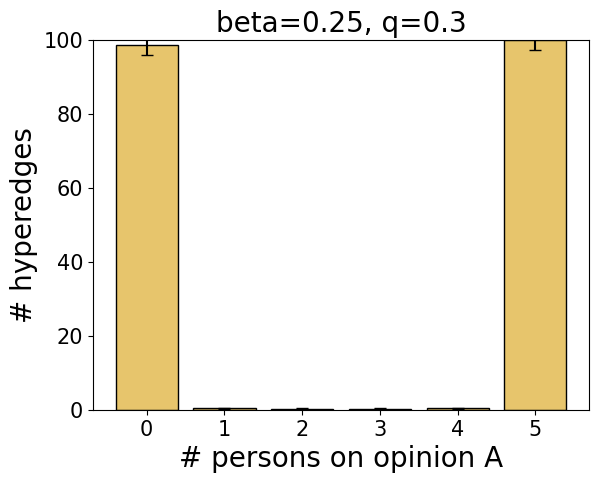

In [16]:
data_mean=[]
data_error=[]

fig, ax = plt.subplots()
ax.set_title(f'{beta=}, {q=}',fontsize=fs)
for i in range(len(results['binned_opinions_home'])):
    data=[results['binned_opinions_home'][i][it][-1] for it in range(iterations)]
    m =mean_confidence_interval(data,0.95)
    data_mean.append(m[0])
    data_error.append(2*m[1])
ax.bar(np.arange(len(results['binned_opinions_home'])), data_mean, 0.8, label=None, color=colors[0],edgecolor = 'black',yerr=data_error, capsize=4,)
# Customize the second subplot
ax.set_xticks(np.arange(len(results['binned_opinions_home'])))
ax.set_ylabel(r'# hyperedges', fontsize=fs)
ax.set_xlabel(r'# persons on opinion A', fontsize=fs)
ax.tick_params(axis='both', labelsize=ts)# Example categories
ax.set_ylim(0,100)
plt.show()


In [17]:
betas=np.arange(0.2,1.05,0.05)
qs=np.arange(0.3,0.8,0.1)

In [18]:
qs

array([0.3, 0.4, 0.5, 0.6, 0.7])

In [19]:
len(betas)

17

In [20]:
len(qs)

5

In [21]:
betas=np.arange(0.2,1.,0.3)
betas

array([0.2, 0.5, 0.8])

In [22]:
qs=np.arange(0.3,1,0.3)
qs

array([0.3, 0.6, 0.9])

In [23]:
data_home

'data/majority_move_lin/'

In [26]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0.1,0.8,0.2)
data_home ="data/majority_move_lin_long/"
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp']
iterations=100

all_res = []
for beta_i, beta in enumerate(betas):
    all_res.append([])
    for q_i,q in enumerate(qs):
        beta_str=str(np.round(beta, 2)).replace('.', '')
        q_str=str(np.round(q, 1)).replace('.', '')
        filename = f"2_regular_edgesize_5_maj_change_lin_beta_{beta_str}_q_{q_str}_r_1.csv"
        df = pd.read_csv(data_home + filename)
        
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            if row != 'sum_opinion_A':
                pdrow=list(df.iloc[[row_i]].values[0])
                for j in range(len(pdrow[2].split(' '))):
                        results[row].append([])
            for i in range(iterations):
                pdrow=list(df.iloc[[i * len(row_names) + row_i]].values[0])        
                if row != 'sum_opinion_A':
                    for j,k in enumerate(pdrow[2].split(' ')):
                        results[row][j].append([])
                    for item in pdrow[2:-1]:
                        for j,k in enumerate(item.split(' ')):
                            results[row][j][i].append(int(k))
                else:
                    try:
                        results[row].append([int(item)for item in pdrow[2:-1]])
                    except:
                        print(i)
                        break
        all_res[beta_i].append(results)

In [27]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0.1,0.8,0.2)
data_home ="data/majority_move_nonlin_long/"
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp']
iterations=100

all_res_nonlin = []
for beta_i, beta in enumerate(betas):
    all_res_nonlin.append([])
    for q_i,q in enumerate(qs):
        beta_str=str(np.round(beta, 2)).replace('.', '')
        q_str=str(np.round(q, 1)).replace('.', '')
        filename = f"2_regular_edgesize_5_maj_change_nonlin_beta_{beta_str}_q_{q_str}_r_05.csv"
        df = pd.read_csv(data_home + filename)
        
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            if row != 'sum_opinion_A':
                pdrow=list(df.iloc[[row_i]].values[0])
                for j in range(len(pdrow[2].split(' '))):
                        results[row].append([])
            for i in range(iterations):
                pdrow=list(df.iloc[[i * len(row_names) + row_i]].values[0])        
                if row != 'sum_opinion_A':
                    for j,k in enumerate(pdrow[2].split(' ')):
                        results[row][j].append([])
                    for item in pdrow[2:-1]:
                        for j,k in enumerate(item.split(' ')):
                            results[row][j][i].append(int(k))
                else:
                    try:
                        results[row].append([int(item)for item in pdrow[2:-1]])
                    except:
                        print(i)
                        break
        all_res_nonlin[beta_i].append(results)

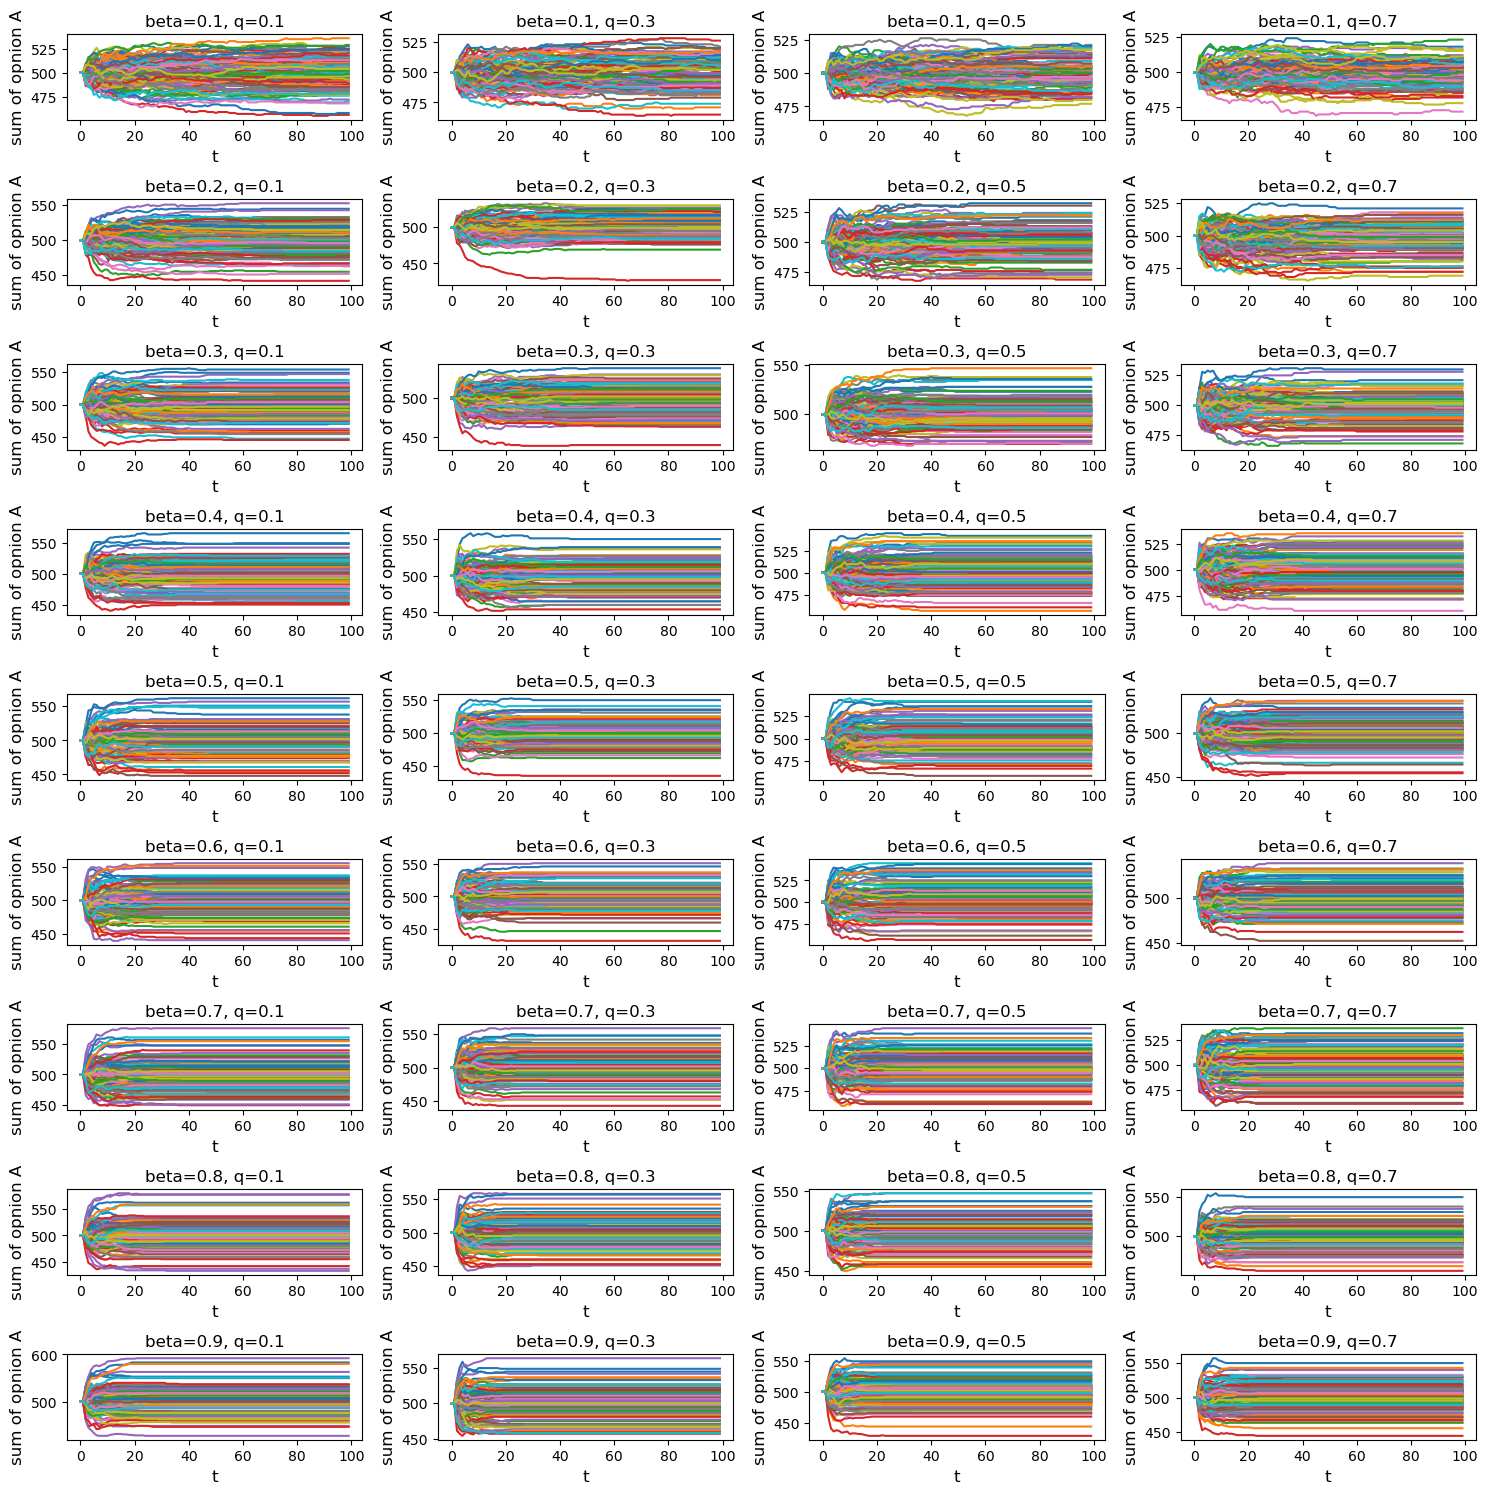

In [43]:
fs=12
ts=10
fig, axes = plt.subplots(len(betas),len(qs), figsize=(15,15))
axes=axes.flatten()
k=0
for i in range(0,len(betas)):
    for j in range(0,len(qs)):
        results=all_res_nonlin[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(100):
            ax.plot(results['sum_opinion_A'][it])
        ax.set_ylabel('sum of opnion A',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        #ax.set_ylim((0,1000))
plt.tight_layout()
plt.savefig('figures/sum_of_A_majority.pdf')
plt.show()
        


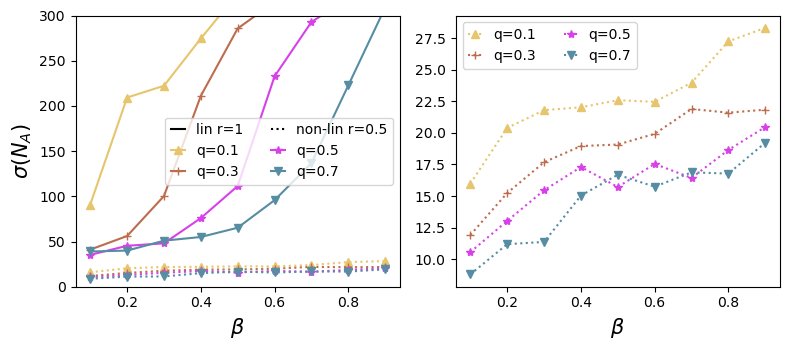

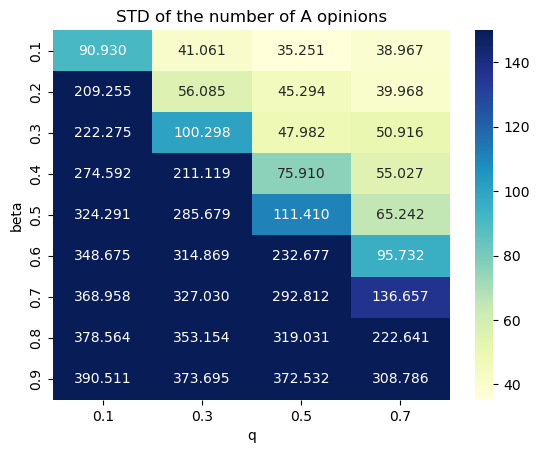

In [31]:
markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
fig,axs = plt.subplots(1,2 ,figsize=(8,3.6))
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.std([results['sum_opinion_A'][it][-1] for it in range(iterations)])
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.std([results['sum_opinion_A'][it][-1] for it in range(iterations)])
        x2.append(s)
    axs[0].plot(betas,x1,label=f'q={qs[j]:.1f} lin',marker=markers[j], color=colors[j])
    axs[0].plot(betas,x2,label=f'q={qs[j]:.1f} nonlin',marker=markers[j], color=colors[j], ls='dotted')
    axs[1].plot(betas,x2,label=f'q={qs[j]:.1f} nonlin',marker=markers[j], color=colors[j], ls='dotted')

axs[0].set_xlabel(r'$\beta$', fontsize=15)
axs[1].set_xlabel(r'$\beta$', fontsize=15)
axs[0].set_ylabel(r'$\sigma(N_A)$', fontsize=15)
axs[0].set_ylim(0,300)

hs=[]
line = mlines.Line2D([], [], color='k', label=r'lin r=1')
hs.append(line)
line = mlines.Line2D([], [], color=colors[0],marker=markers[0], label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1], label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color='k',linestyle='dotted', label=r'non-lin r=0.5')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2], label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3], label=f'q={qs[3]:.1f}')
hs.append(line)

axs[0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=colors[0],marker=markers[0],linestyle='dotted', label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1],linestyle='dotted', label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2],linestyle='dotted', label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3],linestyle='dotted', label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/std.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=150)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

In [32]:
all_res[8][0]['binned_opinions_wp'][9][0][-1]

88

In [33]:
axs

array([<AxesSubplot:xlabel='$\\beta$', ylabel='$\\sigma(N_A)$'>,
       <AxesSubplot:xlabel='$\\beta$'>], dtype=object)

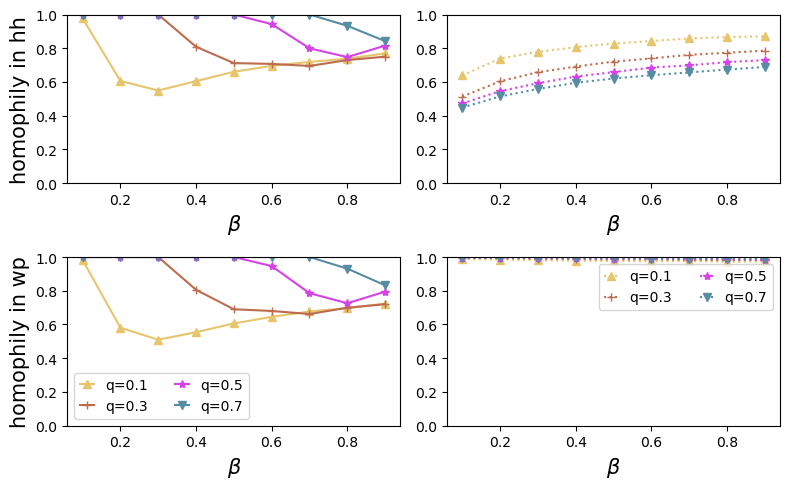

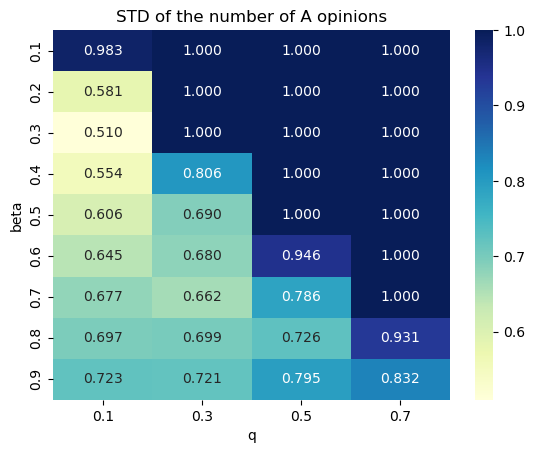

In [34]:
markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
fig,axs = plt.subplots(2,2,figsize=(8,5))
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.mean([(results['binned_opinions_home'][0][it][-1]+results['binned_opinions_home'][5][it][-1])/200 for it in range(iterations)])
        
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.mean([(results['binned_opinions_home'][0][it][-1]+results['binned_opinions_home'][5][it][-1])/200 for it in range(iterations)])
        x2.append(s)
    axs[0][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[0][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[0][0].set_xlabel(r'$\beta$', fontsize=15)
axs[0][1].set_xlabel(r'$\beta$', fontsize=15)
axs[0][0].set_ylabel(r'homophily in hh', fontsize=15)
axs[0][0].set_ylim(0,1)
axs[0][1].set_ylim(0,1)

markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.mean([(results['binned_opinions_wp'][0][it][-1]+results['binned_opinions_wp'][9][it][-1])/200 for it in range(iterations)])
        
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.mean([(results['binned_opinions_wp'][0][it][-1]+results['binned_opinions_wp'][9][it][-1])/200 for it in range(iterations)])
        x2.append(s)
    axs[1][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[1][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[1][0].set_xlabel(r'$\beta$', fontsize=15)
axs[1][1].set_xlabel(r'$\beta$', fontsize=15)
axs[1][0].set_ylabel(r'homophily in wp', fontsize=15)
axs[1][0].set_ylim(0,1)
axs[1][1].set_ylim(0,1)

hs=[]
line = mlines.Line2D([], [], color=colors[0],marker=markers[0], label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1], label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2], label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3], label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=colors[0],marker=markers[0],linestyle='dotted', label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1],linestyle='dotted', label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2],linestyle='dotted', label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3],linestyle='dotted', label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/hom_index.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=1)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

In [169]:
np.where(np.array([False,True,False]))[0][0]

1

In [188]:
np.mean([np.where(((np.array(all_res[i][j]['binned_opinions_home'][0][it])+np.array(all_res[i][j]['binned_opinions_home'][5][it]))/200)>(np.mean((np.array(all_res[i][j]['binned_opinions_wp'][0][it][-10:])+np.array(all_res[i][j]['binned_opinions_wp'][9][it][-10:]))/200)-0.1))[0][0] for it in range(iterations)])


60.29

In [176]:
np.where(((np.array(all_res[i][j]['binned_opinions_home'][0][it])+np.array(all_res[i][j]['binned_opinions_home'][5][it]))/200)>(np.mean((np.array(all_res[i][j]['binned_opinions_wp'][0][it][-5:])+np.array(all_res[i][j]['binned_opinions_wp'][9][it][-5:]))/200)-0.05))[0][0]

67

In [175]:
(np.array(all_res[i][j]['binned_opinions_home'][0][it])+np.array(all_res[i][j]['binned_opinions_home'][5][it]))/200

array([0.06 , 0.065, 0.1  , 0.11 , 0.105, 0.115, 0.15 , 0.165, 0.165,
       0.19 , 0.2  , 0.23 , 0.235, 0.265, 0.28 , 0.29 , 0.3  , 0.31 ,
       0.32 , 0.33 , 0.335, 0.345, 0.365, 0.395, 0.39 , 0.38 , 0.38 ,
       0.36 , 0.385, 0.4  , 0.42 , 0.415, 0.395, 0.415, 0.415, 0.42 ,
       0.42 , 0.415, 0.44 , 0.435, 0.41 , 0.395, 0.415, 0.435, 0.43 ,
       0.42 , 0.4  , 0.415, 0.435, 0.44 , 0.47 , 0.45 , 0.46 , 0.46 ,
       0.46 , 0.445, 0.425, 0.44 , 0.42 , 0.43 , 0.45 , 0.445, 0.47 ,
       0.47 , 0.49 , 0.49 , 0.495, 0.515, 0.51 , 0.505, 0.505, 0.515,
       0.505, 0.49 , 0.51 , 0.505, 0.515, 0.51 , 0.51 , 0.515, 0.52 ,
       0.52 , 0.51 , 0.51 , 0.505, 0.515, 0.52 , 0.545, 0.545, 0.53 ,
       0.535, 0.545, 0.56 , 0.55 , 0.54 , 0.535, 0.55 , 0.535, 0.52 ,
       0.525])

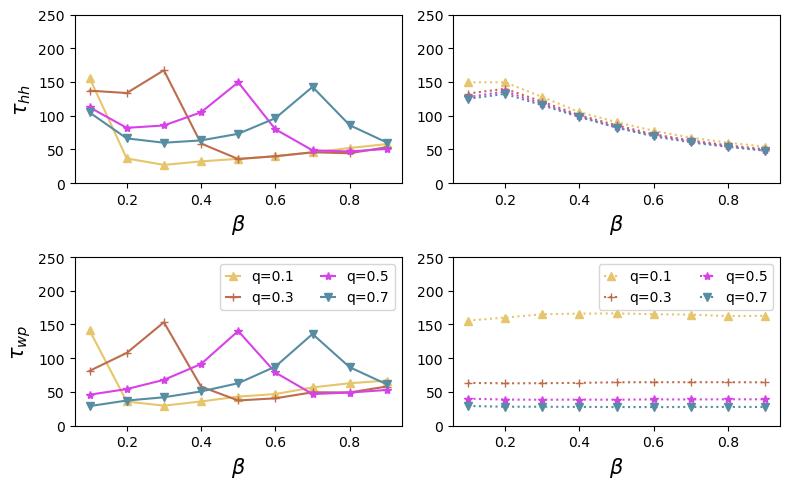

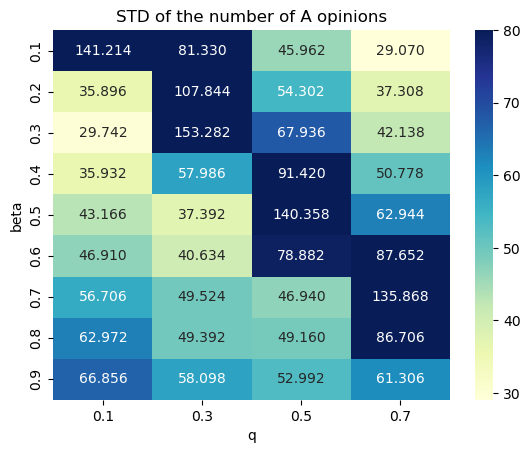

In [18]:
markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
epsilon=0.1

fig,axs = plt.subplots(2,2,figsize=(8,5))
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.mean([np.where(((np.array(results['binned_opinions_home'][0][it])+np.array(results['binned_opinions_home'][5][it]))/200)>(np.mean((np.array(results['binned_opinions_home'][0][it][-5:])+np.array(results['binned_opinions_home'][5][it][-5:]))/200)-epsilon))[0][0] for it in range(iterations)])
        
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.mean([np.where(((np.array(results['binned_opinions_home'][0][it])+np.array(results['binned_opinions_home'][5][it]))/200)>(np.mean((np.array(results['binned_opinions_home'][0][it][-5:])+np.array(results['binned_opinions_home'][5][it][-5:]))/200)-epsilon))[0][0] for it in range(iterations)])
        x2.append(s)
    axs[0][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[0][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[0][0].set_xlabel(r'$\beta$', fontsize=15)
axs[0][1].set_xlabel(r'$\beta$', fontsize=15)
axs[0][0].set_ylabel(r'$\tau_{hh}$', fontsize=15)
axs[0][0].set_ylim(0,250)
axs[0][1].set_ylim(0,250)

markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        s = np.mean([np.where(((np.array(results['binned_opinions_wp'][0][it])+np.array(results['binned_opinions_wp'][9][it]))/200)>(np.mean((np.array(results['binned_opinions_wp'][0][it][-5:])+np.array(results['binned_opinions_wp'][9][it][-5:]))/200)-epsilon))[0][0] for it in range(iterations)])
        
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        s = np.mean([np.where(((np.array(results['binned_opinions_wp'][0][it])+np.array(results['binned_opinions_wp'][9][it]))/200)>(np.mean((np.array(results['binned_opinions_wp'][0][it][-5:])+np.array(results['binned_opinions_wp'][9][it][-5:]))/200)-epsilon))[0][0] for it in range(iterations)])
        x2.append(s)
    axs[1][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[1][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[1][0].set_xlabel(r'$\beta$', fontsize=15)
axs[1][1].set_xlabel(r'$\beta$', fontsize=15)
axs[1][0].set_ylabel(r'$\tau_{wp}$', fontsize=15)
axs[1][0].set_ylim(0,250)
axs[1][1].set_ylim(0,250)

hs=[]
line = mlines.Line2D([], [], color=colors[0],marker=markers[0], label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1], label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2], label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3], label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=colors[0],marker=markers[0],linestyle='dotted', label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1],linestyle='dotted', label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2],linestyle='dotted', label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3],linestyle='dotted', label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/hom_time.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=80)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

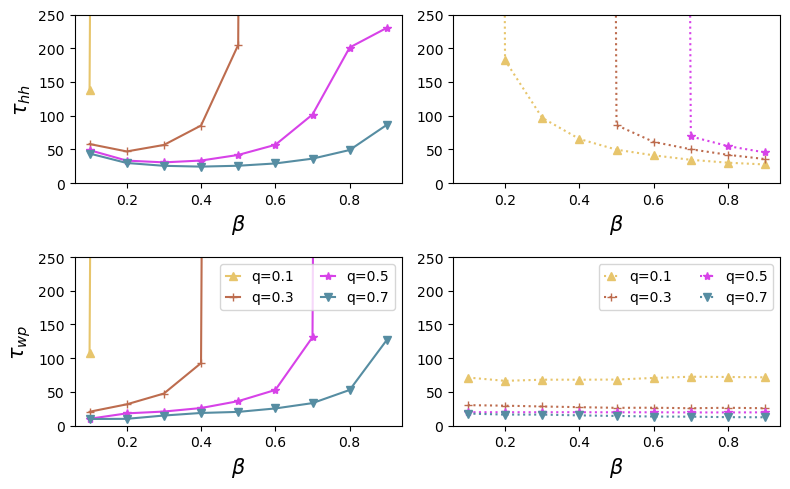

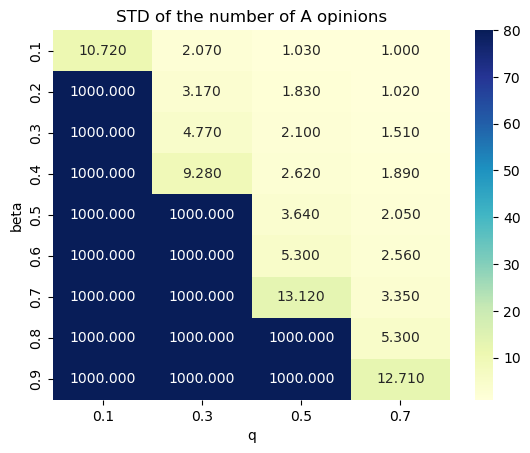

In [38]:
markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
epsilon=0.6

fig,axs = plt.subplots(2,2,figsize=(8,5))
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        try:
            s = np.mean([np.where(((np.array(results['binned_opinions_home'][0][it])+np.array(results['binned_opinions_home'][5][it]))/200)>epsilon)[0][0] for it in range(iterations)])
        except:
            s = 1000
        x1.append(s*10)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        try:
            s = np.mean([np.where(((np.array(results['binned_opinions_home'][0][it])+np.array(results['binned_opinions_home'][5][it]))/200)>epsilon)[0][0] for it in range(iterations)])
        except:
            s = 1000
        x2.append(s*10)
    axs[0][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[0][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[0][0].set_xlabel(r'$\beta$', fontsize=15)
axs[0][1].set_xlabel(r'$\beta$', fontsize=15)
axs[0][0].set_ylabel(r'$\tau_{hh}$', fontsize=15)
axs[0][0].set_ylim(0,250)
axs[0][1].set_ylim(0,250)

markers=['^','+','*','v']
mtx=np.zeros((len(betas),len(qs)))
k=0
for j in range(0,len(qs)):
    x1=[]
    x2=[]
    for i in range(0,len(betas)):
        results=all_res[i][j]
        try:
            s = np.mean([np.where(((np.array(results['binned_opinions_wp'][0][it])+np.array(results['binned_opinions_wp'][9][it]))/200)>epsilon)[0][0] for it in range(iterations)])
        except:
            s = 1000
        x1.append(s*10)
        mtx[i][j]=s
        results=all_res_nonlin[i][j]
        try:
            s = np.mean([np.where(((np.array(results['binned_opinions_wp'][0][it])+np.array(results['binned_opinions_wp'][9][it]))/200)>epsilon)[0][0] for it in range(iterations)])
        
        except:
            s = 1000
        x2.append(s*10)
    axs[1][0].plot(betas,x1,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j])
    axs[1][1].plot(betas,x2,label=f'q={qs[j]:.1f}',marker=markers[j], color=colors[j], ls='dotted')

axs[1][0].set_xlabel(r'$\beta$', fontsize=15)
axs[1][1].set_xlabel(r'$\beta$', fontsize=15)
axs[1][0].set_ylabel(r'$\tau_{wp}$', fontsize=15)
axs[1][0].set_ylim(0,250)
axs[1][1].set_ylim(0,250)

hs=[]
line = mlines.Line2D([], [], color=colors[0],marker=markers[0], label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1], label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2], label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3], label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=colors[0],marker=markers[0],linestyle='dotted', label=f'q={qs[0]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[1],marker=markers[1],linestyle='dotted', label=f'q={qs[1]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[2],marker=markers[2],linestyle='dotted', label=f'q={qs[2]:.1f}')
hs.append(line)
line = mlines.Line2D([], [], color=colors[3],marker=markers[3],linestyle='dotted', label=f'q={qs[3]:.1f}')
hs.append(line)

axs[1][1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/hom_time.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=80)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

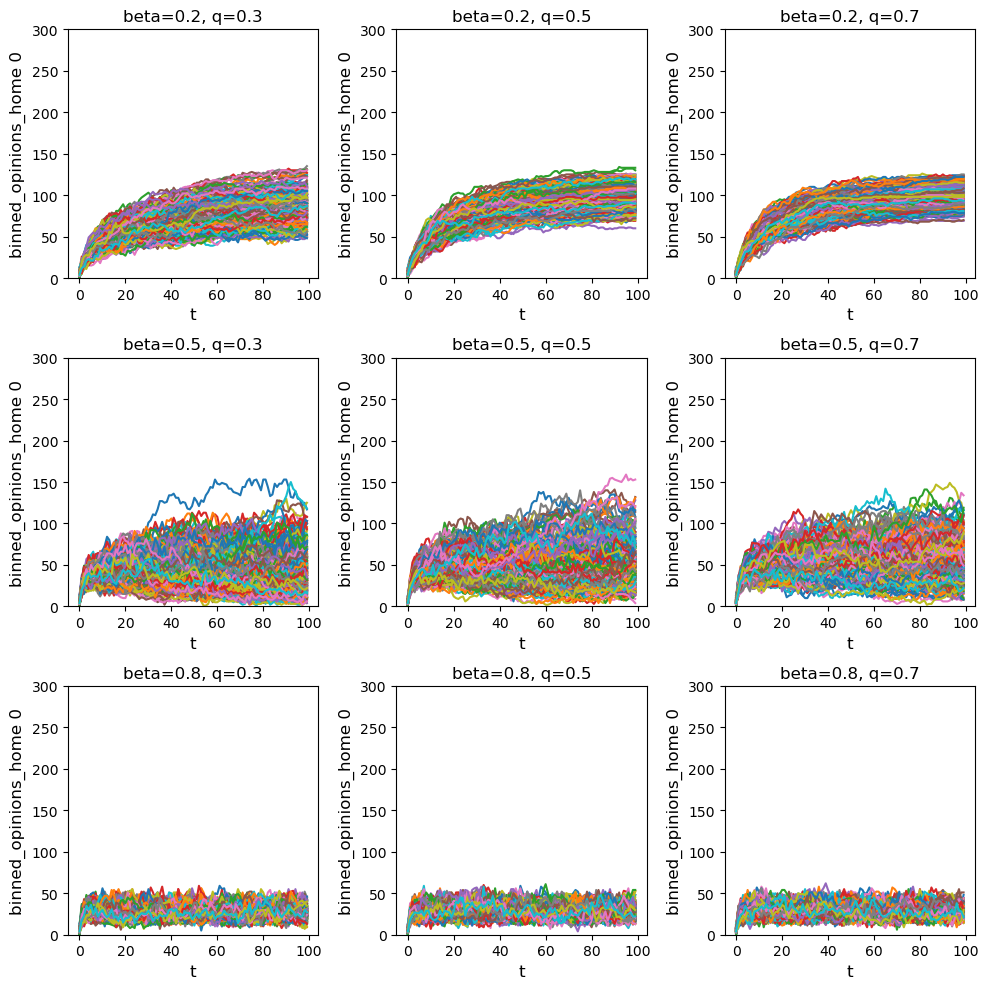

In [45]:
fs=12
ts=10

fig, axes = plt.subplots(len(betas[::6]),len(qs[::2]), figsize=(10,10))
axes=axes.flatten()
k=0
for i in range(0,len(betas),6):
    for j in range(0,len(qs),2):
        results=all_res[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(iterations):
            ax.plot(results['binned_opinions_home'][0][it])
        ax.set_ylabel('binned_opinions_home 0',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        ax.set_ylim((0,300))
plt.tight_layout()

plt.show()
        


In [151]:
for i in range(0,len(betas),6):
    print(betas[i])

0.2
0.49999999999999994
0.7999999999999998


In [44]:
fs=12
ts=10
def hyperedge_opinions(row='binned_opinions_home', color_i=0, typeofedges='home'):
    fig, axes = plt.subplots(len(betas),len(qs), figsize=(15,15))
    axes=axes.flatten()
    k=0
    for i in range(0,len(betas)):
        beta=betas[i]
        for j in range(0,len(qs)):
            results=all_res_nonlin[i][j]
            ax=axes[k]
            
            q=qs[j]
            
            data_mean=[]
            data_error=[]
            print(beta,q)
            ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
            for l in range(len(results[row])):
                data=[results[row][l][it][-1] for it in range(iterations)]
                m =mean_confidence_interval(data,0.95)
                data_mean.append(m[0])
                data_error.append(2*m[1])
            ax.bar(np.arange(len(results[row])), data_mean, 0.8, label=None, color=colors[color_i],edgecolor = 'black',yerr=data_error, capsize=4,)
            # Customize the second subplot
            ax.set_ylim(0,120)
            if typeofedges=='home':
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'# persons on opinion A', fontsize=fs)
                ax.set_xticks(np.arange(len(results[row])))
                
            elif typeofedges=='workplace':
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'rate of persons on opinion A', fontsize=fs)
                ax.set_xticks(np.arange(0,len(results[row]),2), (np.arange(0,len(results[row]),2)+1)/10)
            else:
                ax.set_ylabel(f'# {typeofedges} hyperedges', fontsize=fs)
                ax.set_xlabel(r'size', fontsize=fs)
                ax.set_xticks(np.arange(len(results[row]))+1)
                ax.set_ylim((0,100))
            ax.tick_params(axis='both', labelsize=ts)# Example categories
            
            k+=1
    plt.tight_layout()

0.1 0.1
0.1 0.30000000000000004
0.1 0.5000000000000001
0.1 0.7000000000000001
0.2 0.1
0.2 0.30000000000000004
0.2 0.5000000000000001
0.2 0.7000000000000001
0.30000000000000004 0.1
0.30000000000000004 0.30000000000000004
0.30000000000000004 0.5000000000000001
0.30000000000000004 0.7000000000000001
0.4 0.1
0.4 0.30000000000000004
0.4 0.5000000000000001
0.4 0.7000000000000001
0.5 0.1
0.5 0.30000000000000004
0.5 0.5000000000000001
0.5 0.7000000000000001
0.6 0.1
0.6 0.30000000000000004
0.6 0.5000000000000001
0.6 0.7000000000000001
0.7000000000000001 0.1
0.7000000000000001 0.30000000000000004
0.7000000000000001 0.5000000000000001
0.7000000000000001 0.7000000000000001
0.8 0.1
0.8 0.30000000000000004
0.8 0.5000000000000001
0.8 0.7000000000000001
0.9 0.1
0.9 0.30000000000000004
0.9 0.5000000000000001
0.9 0.7000000000000001


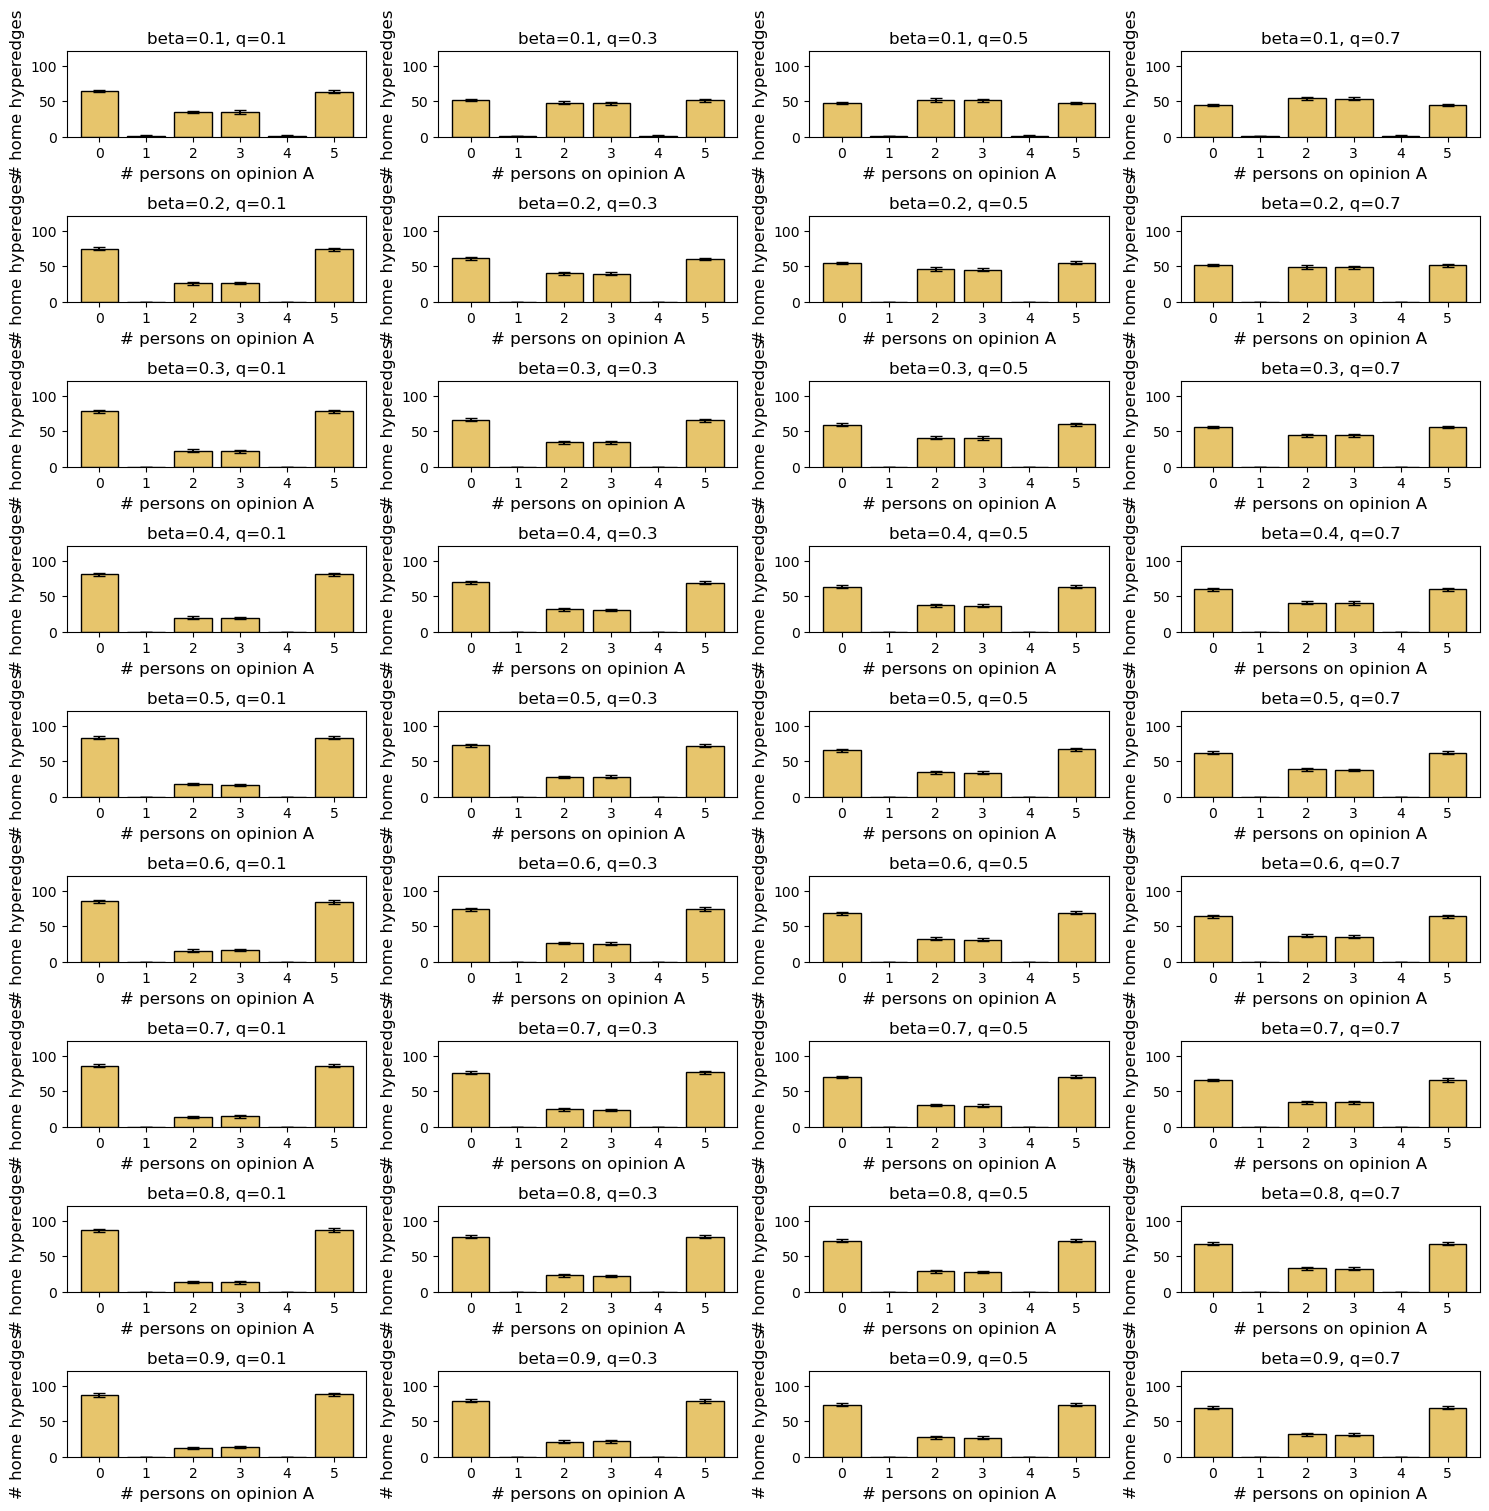

In [45]:
hyperedge_opinions(row='binned_opinions_home', color_i=0)
plt.savefig('figures/binned_opinions_home_majority.pdf')

In [53]:
(0.5+0.4) / 1.5

0.6

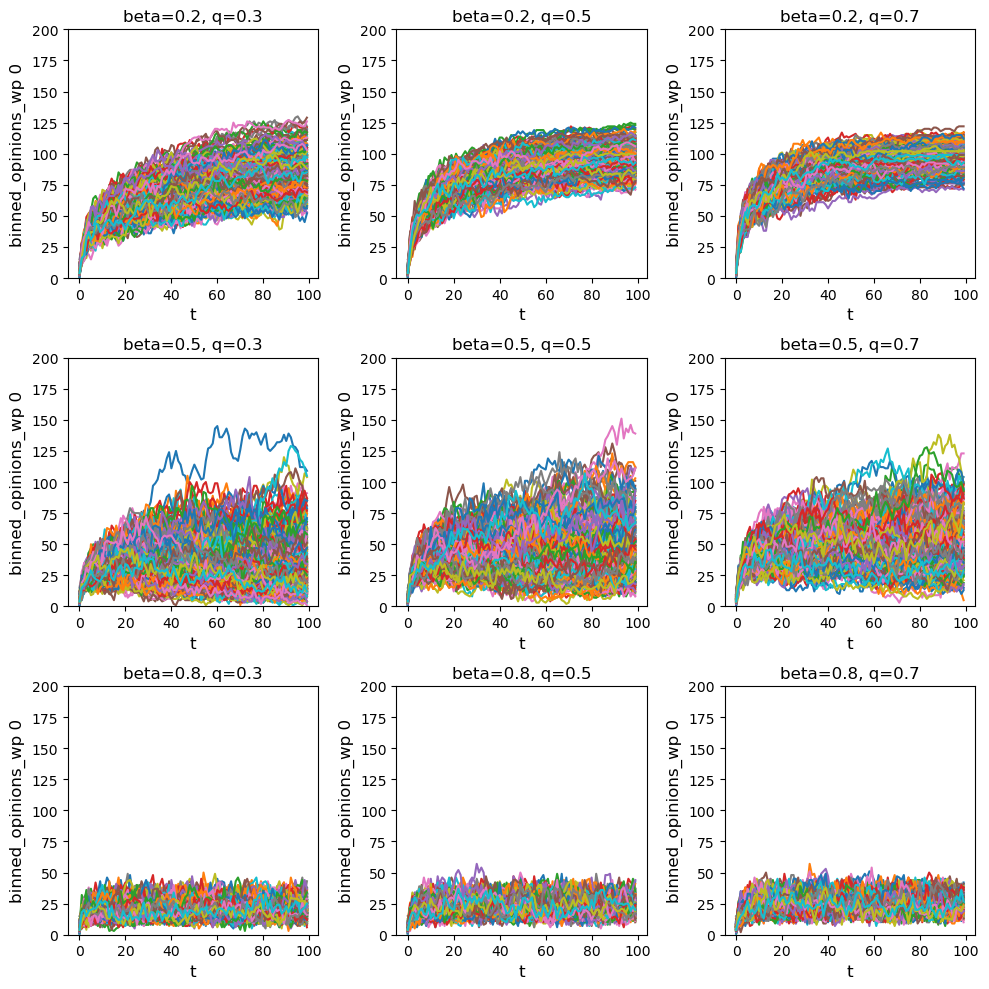

In [43]:
fs=12
ts=10

fig, axes = plt.subplots(len(betas[::6]),len(qs[::2]), figsize=(10,10))
axes=axes.flatten()
k=0
for i in range(0,len(betas),6):
    for j in range(0,len(qs),2):
        results=all_res[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(iterations):
            ax.plot(results['binned_opinions_wp'][0][it])
        ax.set_ylabel('binned_opinions_wp 0',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        ax.set_ylim((0,200))
plt.tight_layout()
plt.show()
        


0.1 0.1
0.1 0.30000000000000004
0.1 0.5000000000000001
0.1 0.7000000000000001
0.2 0.1
0.2 0.30000000000000004
0.2 0.5000000000000001
0.2 0.7000000000000001
0.30000000000000004 0.1
0.30000000000000004 0.30000000000000004
0.30000000000000004 0.5000000000000001
0.30000000000000004 0.7000000000000001
0.4 0.1
0.4 0.30000000000000004
0.4 0.5000000000000001
0.4 0.7000000000000001
0.5 0.1
0.5 0.30000000000000004
0.5 0.5000000000000001
0.5 0.7000000000000001
0.6 0.1
0.6 0.30000000000000004
0.6 0.5000000000000001
0.6 0.7000000000000001
0.7000000000000001 0.1
0.7000000000000001 0.30000000000000004
0.7000000000000001 0.5000000000000001
0.7000000000000001 0.7000000000000001
0.8 0.1
0.8 0.30000000000000004
0.8 0.5000000000000001
0.8 0.7000000000000001
0.9 0.1
0.9 0.30000000000000004
0.9 0.5000000000000001
0.9 0.7000000000000001


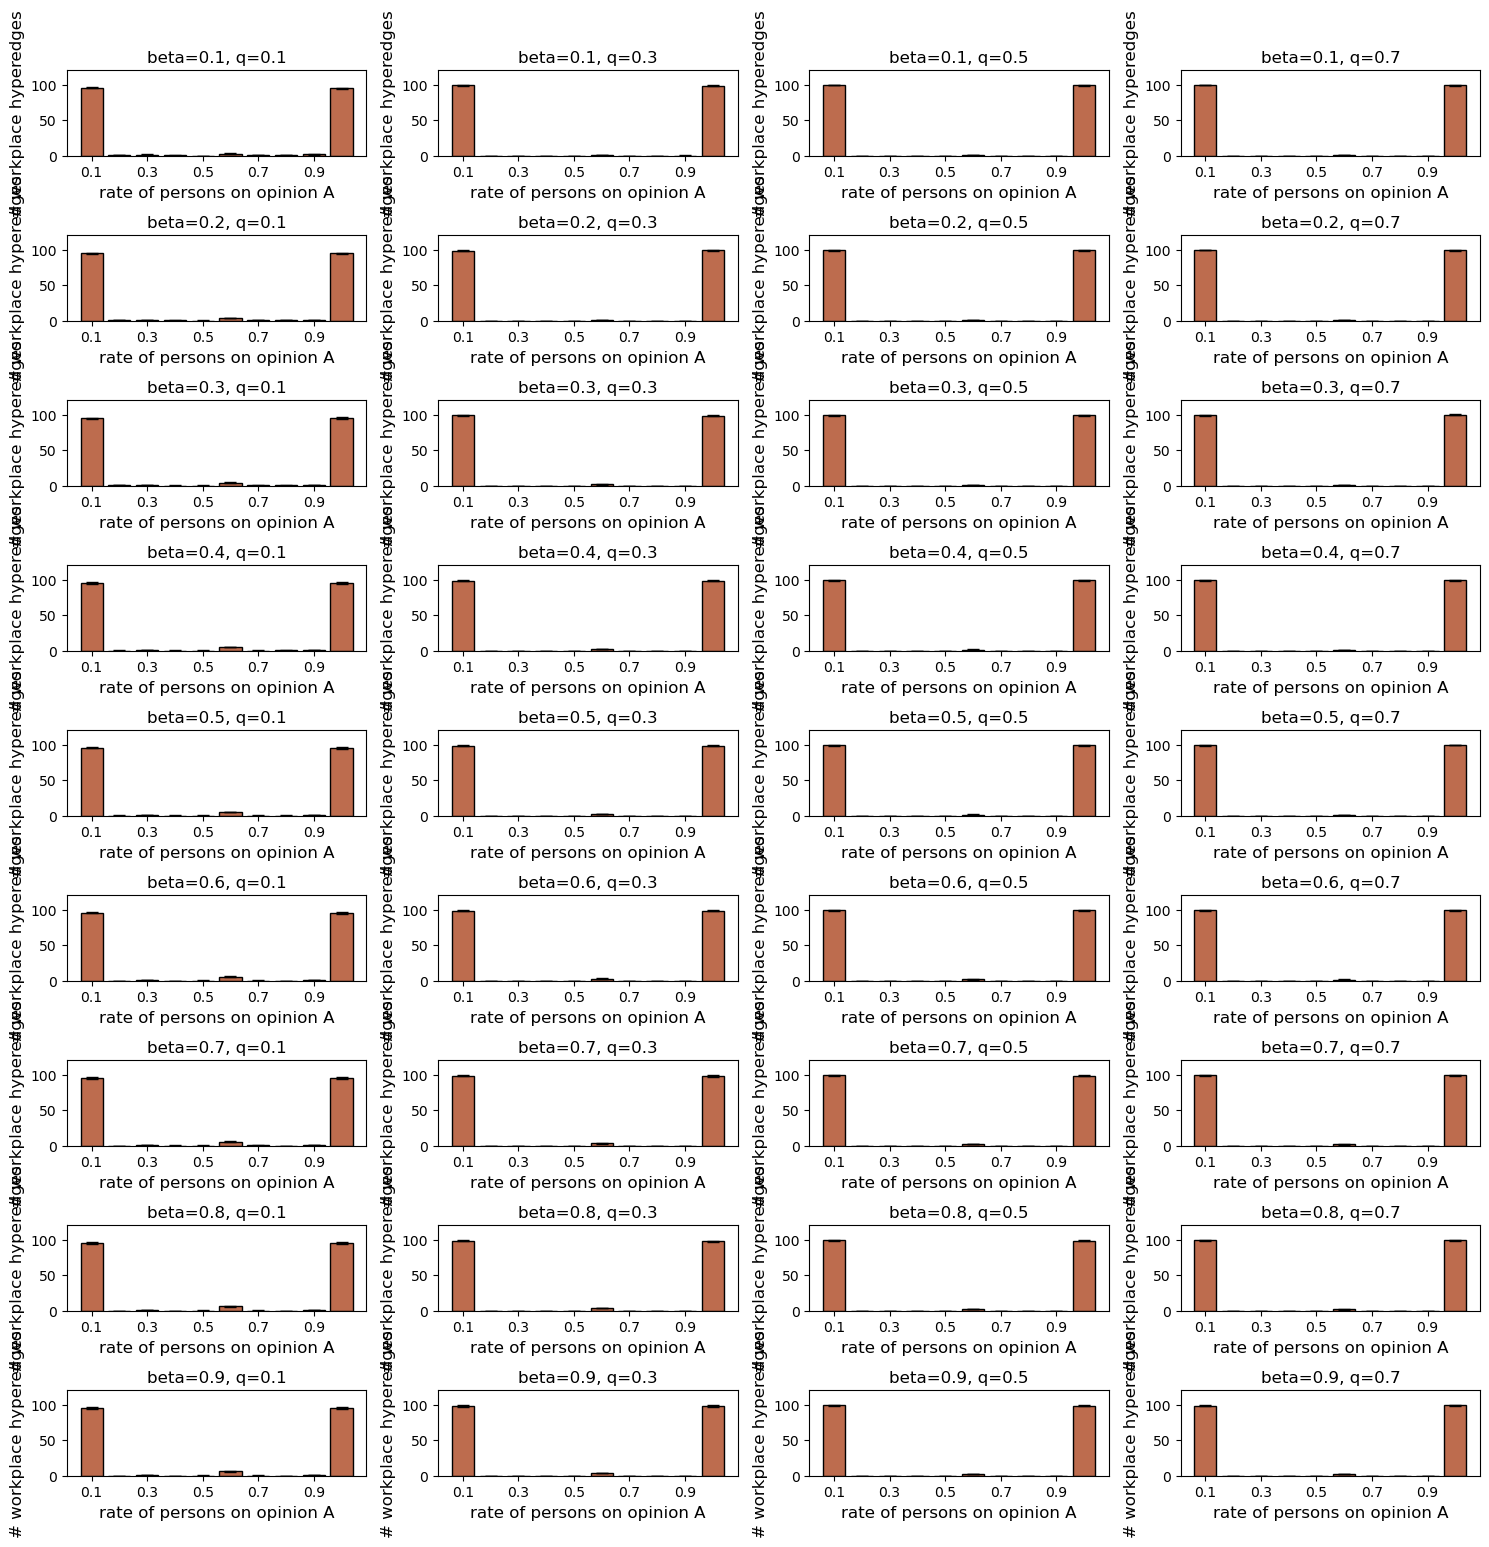

In [25]:
hyperedge_opinions(row='binned_opinions_wp', color_i=1, typeofedges='workplace')
plt.savefig('figures/binned_opinions_wp_majority.pdf')


0.2 0.3
0.2 0.5
0.2 0.7000000000000002
0.49999999999999994 0.3
0.49999999999999994 0.5
0.49999999999999994 0.7000000000000002
0.7999999999999998 0.3
0.7999999999999998 0.5
0.7999999999999998 0.7000000000000002


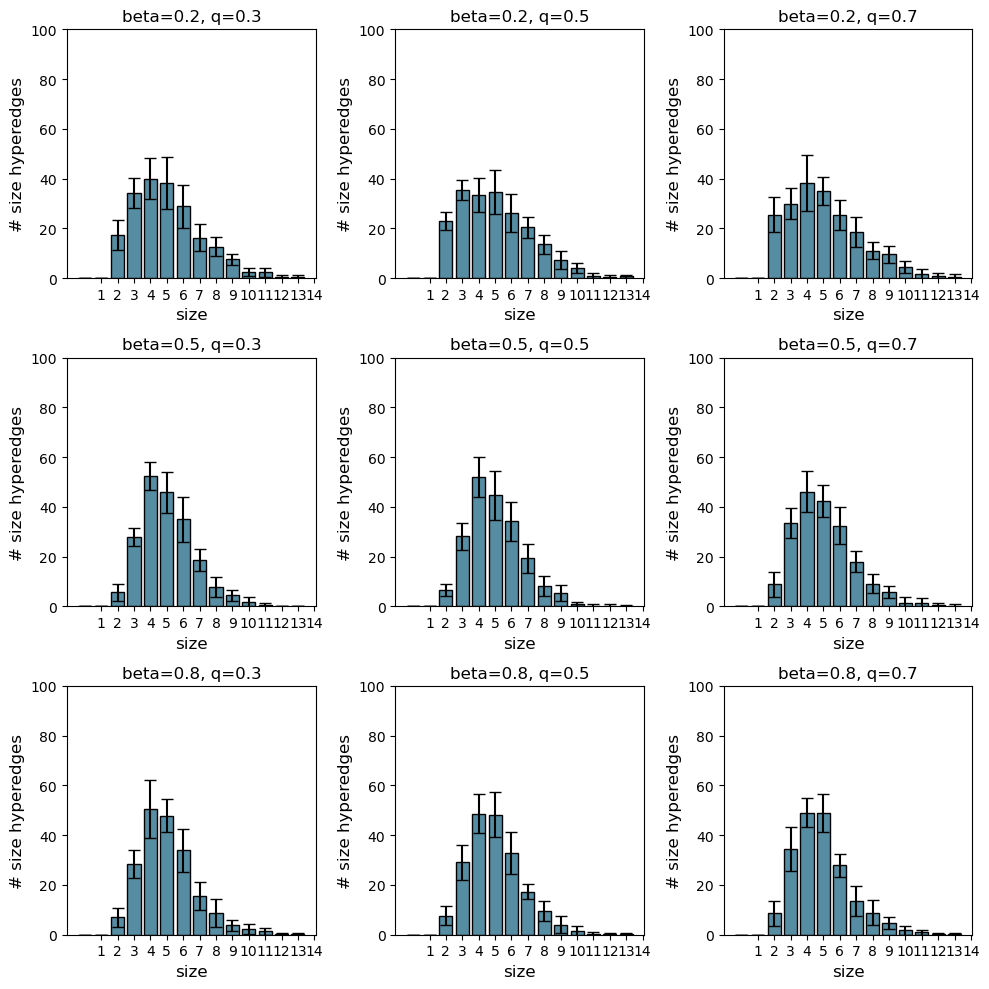

In [63]:
hyperedge_opinions(row='binned_edge_sizes_wp', color_i=2, typeofedges='size')
plt.savefig('figures/binned_edge_sizes_wp_majority.pdf')

In [54]:
data_home ="data/majority_move2/"

In [59]:
all_res2[0][0].keys()

dict_keys(['sum_opinion_A', 'binned_opinions_home', 'binned_opinions_wp', 'binned_edge_sizes_wp', 'move_count', 'op_change_count'])

In [56]:
betas=np.arange(0.2,1.05,0.05)
qs=np.arange(0.3,0.8,0.1)
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp', 'move_count', 'op_change_count']
iterations=10

all_res2 = []
for beta_i, beta in enumerate(betas):
    all_res2.append([])
    for q_i,q in enumerate(qs):
        beta_str=str(np.round(beta, 2)).replace('.', '')
        q_str=str(np.round(q, 1)).replace('.', '')
        filename = f"2_regular_edgesize_5_maj_change_beta_{beta_str}_q_{q_str}.csv"
        df = pd.read_csv(data_home + filename)
        
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            if row != 'sum_opinion_A':
                pdrow=list(df.iloc[[row_i]].values[0])
                for j in range(len(pdrow[2].split(' '))):
                        results[row].append([])
            for i in range(iterations):
                pdrow=list(df.iloc[[i * len(row_names) + row_i]].values[0])        
                if row != 'sum_opinion_A':
                    for j,k in enumerate(pdrow[2].split(' ')):
                        results[row][j].append([])
                    for item in pdrow[2:-1]:
                        for j,k in enumerate(item.split(' ')):
                            results[row][j][i].append(int(k))
                else:
                    try:
                        results[row].append([int(item)for item in pdrow[2:-1]])
                    except:
                        print(i)
                        break
        all_res2[beta_i].append(results)

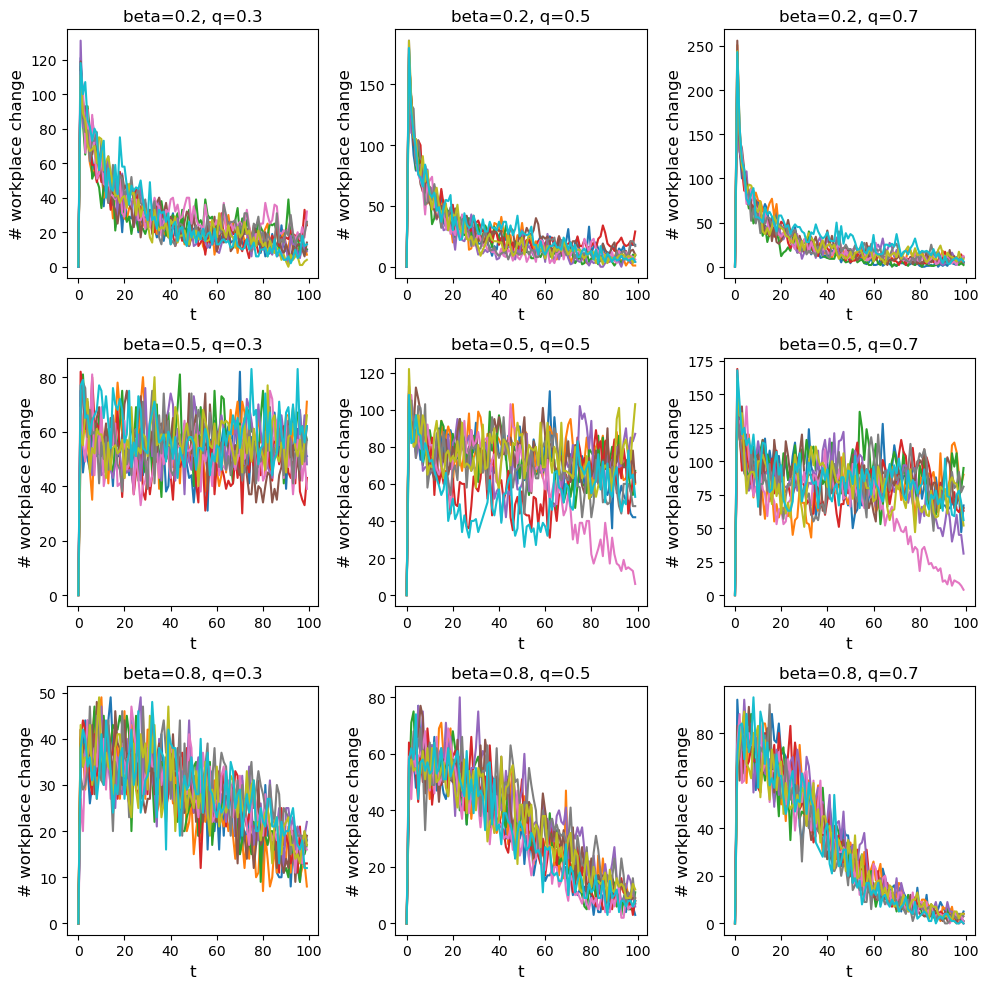

In [65]:
fs=12
ts=10

fig, axes = plt.subplots(len(betas[::6]),len(qs[::2]), figsize=(10,10))
axes=axes.flatten()
k=0
for i in range(0,len(betas),6):
    for j in range(0,len(qs),2):
        results=all_res2[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(iterations):
            ax.plot(results['move_count'][0][it])
        ax.set_ylabel('# workplace change',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        #ax.set_ylim()
plt.tight_layout()
plt.show()
        

In [ ]:
, 'op_change_count'

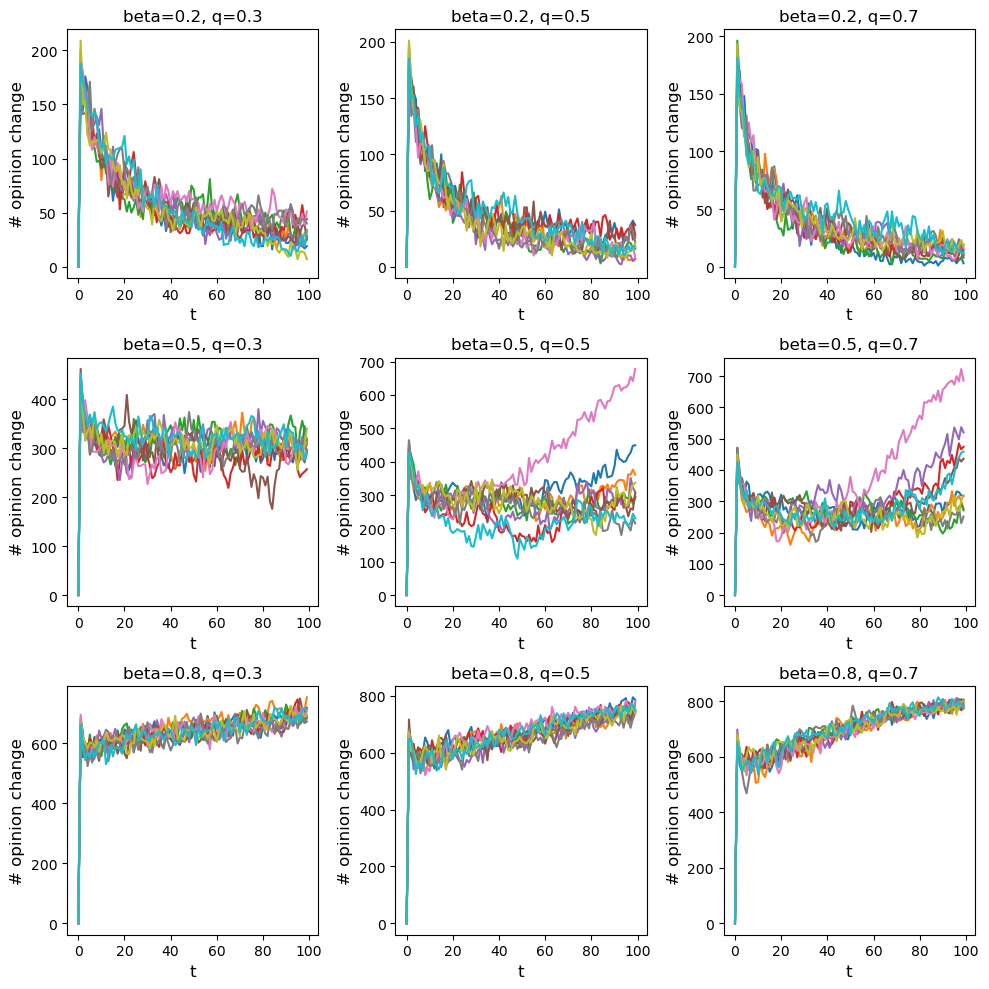

In [66]:
fs=12
ts=10

fig, axes = plt.subplots(len(betas[::6]),len(qs[::2]), figsize=(10,10))
axes=axes.flatten()
k=0
for i in range(0,len(betas),6):
    for j in range(0,len(qs),2):
        results=all_res2[i][j]
        ax=axes[k]
        k+=1
        beta=betas[i]
        q=qs[j]
        
        for it in range(iterations):
            ax.plot(results['op_change_count'][0][it])
        ax.set_ylabel('# opinion change',fontsize=fs)
        ax.set_xlabel('t',fontsize=fs)
        ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=fs)
        ax.tick_params('both', labelsize=ts)
        #ax.set_ylim()
plt.tight_layout()
plt.show()
        